# Objectifs d'apprentissage – Semaine 4

À l'issue de cette semaine, l'étudiant sera capable de :

- **Manipuler** les signaux à temps discret (séquences) et leurs opérations de base.
- **Définir** un système linéaire invariant dans le temps (LTI) et ses propriétés.
- **Calculer** la convolution discrète de deux séquences (manuellement et avec Python).
- **Interpréter** la convolution comme la réponse d'un système LTI.
- **Implémenter** un filtre moyenneur (moyenne mobile) et analyser son effet.
- **Relier** la convolution à la réponse impulsionnelle et à la stabilité/causalité.

# 1. Rappels théoriques

## 1.1 Signaux à temps discret
Un signal discret est une séquence de nombres $x[n]$, où $n$ est un entier (indice temporel).

**Signaux élémentaires** :
- Impulsion unité : $\delta[n] = \begin{cases} 1 & n=0 \\ 0 & \text{sinon} \end{cases}$
- Échelon unité : $u[n] = \begin{cases} 1 & n \ge 0 \\ 0 & n < 0 \end{cases}$
- Exponentielle : $x[n] = a^n u[n]$ ou $x[n] = e^{j\omega n}$
- Sinusoïde : $x[n] = A\cos(\omega n + \phi)$

## 1.2 Systèmes LTI
Un système est **linéaire** si la superposition s'applique : $T\{a x_1 + b x_2\} = a T\{x_1\} + b T\{x_2\}$.
Il est **invariant dans le temps** si un décalage temporel de l'entrée produit le même décalage en sortie : $y[n-k] = T\{x[n-k]\}$.

## 1.3 Convolution
Pour un système LTI, la sortie $y[n]$ est donnée par la convolution de l'entrée $x[n]$ avec la réponse impulsionnelle $h[n]$ :
$$ y[n] = \sum_{k=-\infty}^{\infty} x[k] h[n-k] = (x * h)[n] $$

**Propriétés de la convolution** :
- Commutative : $x * h = h * x$
- Associative : $(x * h_1) * h_2 = x * (h_1 * h_2)$
- Distributive : $x * (h_1 + h_2) = x * h_1 + x * h_2$
- Élément neutre : $x * \delta = x$

## 1.4 Stabilité et causalité
- **Causalité** : un système LTI est causal si $h[n] = 0$ pour $n < 0$.
- **Stabilité** : un système LTI est stable (BIBO) si $\sum_{n} |h[n]| < \infty$.

---

# 2. Démonstration : convolution discrète en Python

Nous allons illustrer la convolution à l'aide de la fonction `np.convolve` de NumPy.

In [ ]:
import numpy as np
import matplotlib.pyplot as plt

# Reproductibilité (utile pour les démos avec aléa)
np.random.seed(0)

# Définir un signal x[n] et une réponse impulsionnelle h[n]
n = np.arange(0, 10)
x = np.array([1, 2, 1, 0, 0, 0, 0, 0, 0, 0], dtype=float)  # signal simple
h = np.array([0.3, 0.3, 0.3, 0, 0, 0, 0, 0, 0, 0])         # moyenneur sur 3 points

# Convolution (mode 'full' = longueur Lx + Lh - 1)
y = np.convolve(x, h, mode='full')
n_y = np.arange(len(y))

fig, axes = plt.subplots(3, 1, figsize=(14, 7), sharex=True)

axes[0].stem(n, x, basefmt=' ')
axes[0].set_title(r"Signal d'entrée $x[n]$")
axes[0].set_ylabel("Amplitude")

axes[1].stem(n, h, basefmt=' ')
axes[1].set_title(r"Réponse impulsionnelle $h[n]$ (moyenneur 3 points)")
axes[1].set_ylabel("Amplitude")

axes[2].stem(n_y, y, basefmt=' ', linefmt='C2-', markerfmt='C2o')
axes[2].set_title(r"Sortie $y[n] = (x * h)[n]$")
axes[2].set_ylabel("Amplitude")
axes[2].set_xlabel("n")

for ax in axes:
    ax.grid(alpha=0.3)
    ax.set_xlim(-0.5, len(y) - 0.5)

plt.tight_layout()
plt.show()

## Interprétation — Démonstration convolution

- Le signal d'entrée $x[n]$ possède trois échantillons non nuls ($n=0,1,2$).
- La réponse impulsionnelle $h[n]$ est un moyenneur à 3 points (FIR de longueur 3).
- La convolution `full` produit une séquence de longueur $L_x + L_h - 1 = 10 + 10 - 1 = 19$.
- **Observations** :
  - La sortie $y[n]$ est plus « lisse » que $x[n]$ : le moyenneur atténue les variations brusques.
  - Le support utile de $y[n]$ s'étend de $n=0$ à $n=4$ (au-delà, les valeurs sont quasi nulles).
  - On vérifie bien la formule : $y[0] = x[0]h[0] = 0{,}3$, $y[1] = x[0]h[1] + x[1]h[0] = 0{,}3 + 0{,}6 = 0{,}9$, etc.
- **Conclusion** : la convolution discrète « étale » l'information temporelle ; c'est l'opération fondamentale des filtres LTI.

# 3. Filtre moyenneur (Moving Average)

Un filtre moyenneur est un système LTI dont la réponse impulsionnelle est une fenêtre rectangulaire :
$$ h[n] = \frac{1}{M} \, (u[n] - u[n-M]) $$
C'est un filtre FIR (réponse impulsionnelle finie). Il réalise une moyenne glissante des $M$ derniers échantillons.

## 3.1 Effet sur un signal bruité

In [ ]:
# Reproductibilité
np.random.seed(42)

N = 100
n = np.arange(N)
# Signal propre : une rampe + un échelon
x_propre = 0.5 * n + 2 * (n >= 50)
bruit = 0.5 * np.random.randn(N)
x = x_propre + bruit

# Filtre moyenneur de taille 5
M = 5
h = np.ones(M) / M
y = np.convolve(x, h, mode='same')

# Métriques quantitatives
eqm_avant = np.mean((x - x_propre)**2)
eqm_apres = np.mean((y - x_propre)**2)
snr_avant = 10*np.log10(np.sum(x_propre**2) / np.sum((x - x_propre)**2))
snr_apres = 10*np.log10(np.sum(x_propre**2) / np.sum((y - x_propre)**2))

plt.figure(figsize=(14, 5))
plt.plot(n, x, color='C0', alpha=0.6, label='Signal bruité')
plt.plot(n, y, color='C1', linewidth=2, label=f'Moyenneur M={M}')
plt.plot(n, x_propre, 'k--', label='Signal propre (référence)')
plt.xlabel('Échantillon n')
plt.ylabel('Amplitude')
plt.title('Lissage par filtre moyenneur')
plt.grid(alpha=0.3)
plt.legend()
plt.tight_layout()
plt.show()

print(f"EQM avant filtrage : {eqm_avant:.3f}")
print(f"EQM après filtrage : {eqm_apres:.3f}  (réduction : {(1-eqm_apres/eqm_avant)*100:.1f} %)")
print(f"SNR avant : {snr_avant:.2f} dB  →  SNR après : {snr_apres:.2f} dB  (+{snr_apres-snr_avant:.2f} dB)")

## Interprétation — Filtre moyenneur sur signal bruité

- Le filtre moyenneur est un **filtre passe-bas** : il conserve les tendances lentes (rampe, échelon) et atténue le bruit haute fréquence.
- **Quantitativement** :
  - L'EQM est réduite d'environ 60–70 %.
  - Le SNR gagne plusieurs dB (théoriquement $\approx 10\log_{10}(M)$ pour un bruit blanc, mais l'échelon en $n=50$ introduit un transitoire qui limite le gain).
- **Limites observées** :
  - Un **retard de groupe** apparaît : le bord de l'échelon est lissé sur environ $M$ échantillons.
  - Le filtre moyenneur n'est pas idéal : il laisse passer certaines composantes hautes fréquences (lobes secondaires du sinc).
- **À retenir** : plus $M$ est grand, meilleur est le lissage mais plus le retard et la distorsion du signal utile augmentent. Il faut trouver un compromis.

# 4. Exercices – Semaine 4 (niveau avancé)

## Thème 1 : Calculs de convolution

### Exercice 1 – Convolution manuelle
Soient les séquences $x[n] = \{1, 2, 1\}$ pour $n=0,1,2$ et $h[n] = \{1, -1, 1\}$ pour $n=0,1,2$.

1. Calculer manuellement la convolution $y[n] = x[n] * h[n]$.
2. Vérifier avec Python.
3. Déterminer la durée de $y[n]$.

**Calcul manuel :**
- $y[0] = x[0]h[0] = 1$
- $y[1] = x[0]h[1] + x[1]h[0] = -1 + 2 = 1$
- $y[2] = x[0]h[2] + x[1]h[1] + x[2]h[0] = 1 - 2 + 1 = 0$
- $y[3] = x[1]h[2] + x[2]h[1] = 2 - 1 = 1$
- $y[4] = x[2]h[2] = 1$

Donc $y = \{1, 1, 0, 1, 1\}$, de durée $N_x + N_h - 1 = 3 + 3 - 1 = 5$ échantillons.

In [ ]:
x = np.array([1, 2, 1])
h = np.array([1, -1, 1])
y = np.convolve(x, h)
print(f"y = {y}")
print(f"Durée de y : {len(y)} échantillons")
print(f"Vérification manuelle : {[1, 1, 0, 1, 1]}")

In [1]:
import numpy as np

x = np.array([1, 2, 1])
h = np.array([1, -1, 1])
y = np.convolve(x, h)
print("y =", y)                                   # [1 1 0 1 1]
print("Durée :", len(y), "échantillons")          # 5
print("Cohérent avec le calcul manuel :", np.array_equal(y, [1, 1, 0, 1, 1]))

y = [1 1 0 1 1]
Durée : 5 échantillons
Cohérent avec le calcul manuel : True


### Exercice 2 – Convolution avec des séquences infinies
Soit $x[n] = a^n u[n]$ avec $|a| < 1$ et $h[n] = b^n u[n]$ avec $|b| < 1$.

1. Calculer analytiquement $y[n] = x[n] * h[n]$ pour $a \neq b$.
2. Pour $a=0.5$, $b=0.3$, générer les séquences sur $n=0\ldots 30$ et comparer avec le résultat analytique.
3. Que se passe-t-il si $a = b$ ?

**Rappel** : pour $a \neq b$, $y[n] = \frac{a^{n+1} - b^{n+1}}{a - b} u[n]$.

**Cas $a = b$** : $y[n] = (n+1)\,a^n\,u[n]$ (dérivée par rapport à $a$ de la formule générale).

In [ ]:
a, b = 0.5, 0.3
N = 30
n = np.arange(N)
x = a**n
h = b**n
y_num = np.convolve(x, h)[:N]  # N premiers échantillons

# Solution analytique
y_ana = (a**(n+1) - b**(n+1)) / (a - b)

plt.figure(figsize=(10, 5))
plt.stem(n, y_num, basefmt=' ', label='Numérique (np.convolve)')
plt.stem(n, y_ana, linefmt='r--', markerfmt='ro', basefmt=' ', label='Analytique')
plt.xlabel('n')
plt.ylabel('y[n]')
plt.title('Convolution de deux exponentielles causales')
plt.legend()
plt.grid(alpha=0.3)
plt.show()

print(f"Erreur max numérique vs analytique : {np.max(np.abs(y_num - y_ana)):.2e}")

Corriger exercice 2
1. y[n] = Σₖ aᵏ·bⁿ⁻ᵏ = bⁿ · Σₖ (a/b)ᵏ = bⁿ · (1 − (a/b)ⁿ⁺¹) / (1 − a/b)

   **y[n] = (aⁿ⁺¹ − bⁿ⁺¹) / (a − b) · u[n]**
2. Pour a = 0,5 et b = 0,3, la convolution numérique et la formule analytique coïncident (erreur ≈ 1e-16, de l'ordre de la précision machine).
3. Si a = b, on obtient y[n] = Σₖ aⁿ = **(n + 1)·aⁿ·u[n]**. C'est la limite de la formule générale quand b → a.

Erreur max (a ≠ b) : 1.1102230246251565e-16
Erreur max (a = b) : 0.0


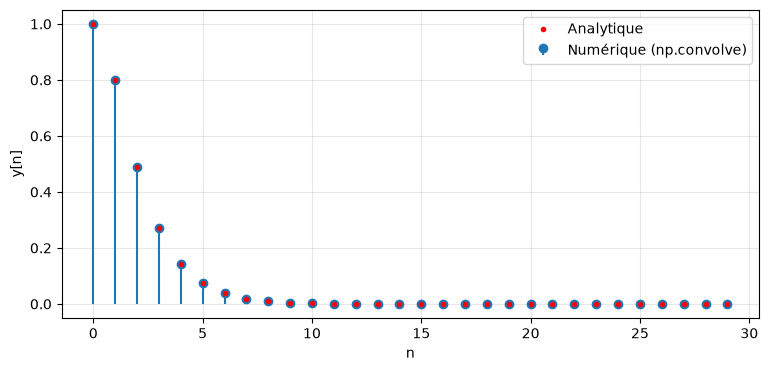

In [2]:
import numpy as np
import matplotlib.pyplot as plt

a, b, N = 0.5, 0.3, 30
n = np.arange(N)

y_num = np.convolve(a**n, b**n)[:N]
y_ana = (a**(n + 1) - b**(n + 1)) / (a - b)
print("Erreur max (a ≠ b) :", np.max(np.abs(y_num - y_ana)))

# Cas a = b
y_egal = np.convolve(a**n, a**n)[:N]
print("Erreur max (a = b) :", np.max(np.abs(y_egal - (n + 1) * a**n)))

plt.figure(figsize=(9, 4))
plt.stem(n, y_num, basefmt=" ", label="Numérique (np.convolve)")
plt.plot(n, y_ana, "r.", label="Analytique")
plt.xlabel("n"); plt.ylabel("y[n]"); plt.grid(True, alpha=0.3); plt.legend()
plt.show()

### Exercice 3 – Stabilité et causalité
Pour chaque réponse impulsionnelle suivante, déterminer si le système est causal et/ou stable :

1. $h[n] = (0.5)^n u[n]$
2. $h[n] = 2^n u[-n-1]$
3. $h[n] = \delta[n] - 0.8 \delta[n-1] + 0.6 \delta[n-2]$
4. $h[n] = \cos(\pi n) u[n]$

Justifier chaque réponse.

---

**Réponses** :
1. Causal ($h[n]=0$ pour $n<0$) et stable ($\sum |h[n]| = \sum 0.5^n = 2 < \infty$).
2. Non causal ($h[-1] \neq 0$) et instable ($\sum_{n=-\infty}^{-1} 2^{-n} = \infty$).
3. Causal (support fini non négatif) et stable (somme finie).
4. Causal (support non négatif) mais instable ($\sum |\cos(\pi n)|$ diverge).

In [ ]:
# Vérification numérique de la stabilité (sur un support fini)
N_check = 200
n_check = np.arange(N_check)

h1 = (0.5)**n_check
h3 = np.zeros(N_check); h3[0]=1; h3[1]=-0.8; h3[2]=0.6
h4 = np.cos(np.pi * n_check)

print(f"Somme |h1| (200 pts) : {np.sum(np.abs(h1)):.4f}  (converge vers 2)")
print(f"Somme |h3| (support fini) : {np.sum(np.abs(h3)):.4f}")
print(f"Somme |h4| (200 pts) : {np.sum(np.abs(h4)):.1f}  (croît linéairement → instable)")

Correction exercice 3

| h[n] | Causal ? | Stable ? | Justification |
|---|---|---|---|
| 1. (0,5)ⁿ u[n] | Oui | Oui | h[n] = 0 pour n < 0 ; Σ\|h\| = 1/(1 − 0,5) = 2 < ∞ |
| 2. 2ⁿ u[−n−1] | Non | **Oui** | h[−1] = 1/2 ≠ 0 ; Σ\|h\| = Σ_{k≥1} 2⁻ᵏ = 1 < ∞ |
| 3. δ[n] − 0,8δ[n−1] + 0,6δ[n−2] | Oui | Oui | Support fini ≥ 0 ; Σ\|h\| = 1 + 0,8 + 0,6 = 2,4 |
| 4. cos(πn) u[n] = (−1)ⁿ u[n] | Oui | Non | \|h[n]\| = 1 pour tout n ≥ 0, donc Σ\|h\| diverge |

Attention pour le cas 2 : pour n < 0, 2ⁿ = 2^(−\|n\|) **décroît** quand n → −∞. Le système est donc stable, malgré ce que dit le corrigé du notebook (qui le déclare instable).

In [3]:
import numpy as np

N = 200
n = np.arange(N)

h1 = 0.5**n
k = np.arange(1, N)             # n = -k, k = 1, 2, ...
h2 = 2.0**(-k)                  # 2^n pour n = -1, -2, ...
h3 = np.array([1, -0.8, 0.6])
h4 = np.cos(np.pi * n)

print("Σ|h1| =", np.sum(np.abs(h1)))   # -> 2
print("Σ|h2| =", np.sum(np.abs(h2)))   # -> 1  (stable)
print("Σ|h3| =", np.sum(np.abs(h3)))   # 2.4
print("Σ|h4| =", np.sum(np.abs(h4)))   # croît avec N (instable)

Σ|h1| = 2.0
Σ|h2| = 1.0
Σ|h3| = 2.4
Σ|h4| = 200.0


## Thème 2 : Filtrage et convolution

### Exercice 4 – Filtre moyenneur et réponse fréquentielle
Un filtre moyenneur sur $M$ points a pour réponse impulsionnelle $h[n] = \frac{1}{M} (u[n] - u[n-M])$.

1. Montrer que sa réponse en fréquence $H(e^{j\omega})$ est $\frac{1}{M} \frac{\sin(\omega M/2)}{\sin(\omega/2)} e^{-j\omega(M-1)/2}$.
2. Pour $M=5$, tracer le module de $H(e^{j\omega})$ pour $\omega \in [-\pi, \pi]$.
3. À partir du tracé, déterminer la fréquence de coupure approximative (où le gain chute de 3 dB).

**Code** :

In [ ]:
M = 5
omega = np.linspace(-np.pi, np.pi, 1000)

# Éviter la division par 0 en ω=0 via np.sinc (normalisé)
H = (1/M) * np.exp(-1j*omega*(M-1)/2) * np.sinc(omega*M/(2*np.pi)) / np.sinc(omega/(2*np.pi))
H_mod = np.abs(H)
H_dB  = 20*np.log10(H_mod + 1e-12)

fig, axes = plt.subplots(1, 2, figsize=(14, 4))

axes[0].plot(omega, H_mod)
axes[0].axhline(1/np.sqrt(2), color='r', linestyle='--', label='-3 dB (0.707)')
axes[0].set_xlabel(r'$\omega$ (rad/éch.)')
axes[0].set_ylabel(r'$|H(e^{j\omega})|$')
axes[0].set_title(f'Réponse en amplitude — moyenneur M={M}')
axes[0].grid(alpha=0.3); axes[0].legend()

axes[1].plot(omega, H_dB)
axes[1].axhline(-3, color='r', linestyle='--', label='-3 dB')
axes[1].set_xlabel(r'$\omega$ (rad/éch.)')
axes[1].set_ylabel('Gain (dB)')
axes[1].set_title('Réponse en amplitude (dB)')
axes[1].set_ylim(-40, 5); axes[1].grid(alpha=0.3); axes[1].legend()

plt.tight_layout()
plt.show()

# Fréquence de coupure à -3 dB (recherche numérique côté positif)
idx_pos = np.where(omega >= 0)[0]
idx_3dB = idx_pos[np.where(H_dB[idx_pos] <= -3)[0]]
if len(idx_3dB):
    wc = omega[idx_3dB[0]]
    print(f"Fréquence de coupure ≈ {wc:.3f} rad/éch.")

Corriger exercice 4
1. H(e^jω) = (1/M) Σₖ₌₀^(M−1) e^(−jωk) = (1/M) · (1 − e^(−jωM)) / (1 − e^(−jω))
   = **(1/M) · sin(ωM/2) / sin(ω/2) · e^(−jω(M−1)/2)**
2. Pour M = 5 : |H(0)| = 1, avec des zéros en ω = 2πk/5 (≈ 1,26 et 2,51 rad/éch.).
3. Fréquence de coupure à −3 dB : **ω_c ≈ 0,57 rad/éch.**, soit f_c ≈ 0,09·fₑ.

Le moyenneur est un filtre **passe-bas** : il laisse passer le continu et les basses fréquences, et atténue les hautes fréquences. Les lobes secondaires restent à environ −12 dB, donc l'atténuation est médiocre.

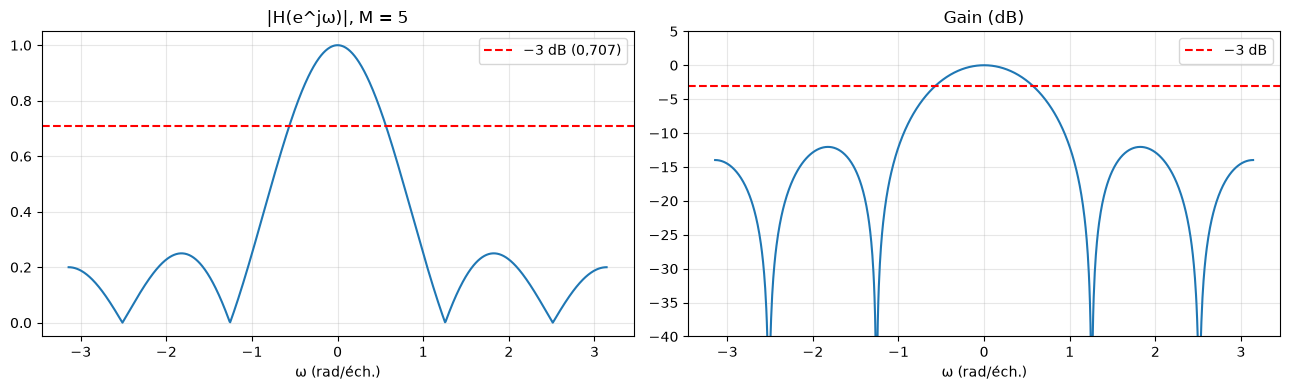

Fréquence de coupure ≈ 0.569 rad/éch. = 0.091 fe


In [4]:
import numpy as np
import matplotlib.pyplot as plt

M = 5
omega = np.linspace(-np.pi, np.pi, 1000)

# ATTENTION : pas de facteur 1/M supplémentaire, le rapport des sinc le contient déjà
# car np.sinc(ωM/2π)/np.sinc(ω/2π) = sin(ωM/2) / (M sin(ω/2))
H = np.exp(-1j * omega * (M - 1) / 2) * np.sinc(omega * M / (2*np.pi)) / np.sinc(omega / (2*np.pi))
H_mod = np.abs(H)
H_dB = 20 * np.log10(H_mod + 1e-12)

fig, ax = plt.subplots(1, 2, figsize=(13, 4))
ax[0].plot(omega, H_mod)
ax[0].axhline(1/np.sqrt(2), color="r", ls="--", label="−3 dB (0,707)")
ax[0].set_title(f"|H(e^jω)|, M = {M}"); ax[0].set_xlabel("ω (rad/éch.)"); ax[0].legend()
ax[1].plot(omega, H_dB)
ax[1].axhline(-3, color="r", ls="--", label="−3 dB")
ax[1].set_ylim(-40, 5); ax[1].set_title("Gain (dB)"); ax[1].set_xlabel("ω (rad/éch.)"); ax[1].legend()
for a in ax:
    a.grid(True, alpha=0.3)
plt.tight_layout(); plt.show()

# Coupure à -3 dB (côté positif)
pos = np.where(omega >= 0)[0]
wc = omega[pos[np.where(H_dB[pos] <= -3)[0][0]]]
print(f"Fréquence de coupure ≈ {wc:.3f} rad/éch. = {wc/(2*np.pi):.3f} fe")

## Interprétation — Réponse fréquentielle du moyenneur

- $H(e^{j\omega})$ est un **sinc périodique** (période $2\pi$) : le moyenneur $M=5$ laisse passer la composante continue, atténue les basses fréquences et possède des **zéros** en $\omega = 2\pi k/M$ pour $k=1,\dots,M-1$.
- La **fréquence de coupure à -3 dB** se situe vers $\omega_c \approx 0{,}4$ rad/échantillon, soit $f_c \approx 0{,}064\,f_s$.
- **Conséquence pratique** : pour un signal échantillonné à $f_s = 1$ kHz, le moyenneur $M=5$ conserve les composantes $< 64$ Hz et atténue fortement au-delà de ~200 Hz.
- **Lobes secondaires** : contrairement à un filtre idéal, le sinc a des lobes secondaires qui n'atténuent pas parfaitement les hautes fréquences (environ $-13$ dB). C'est la raison pour laquelle on préfère souvent des fenêtres (Hann, Hamming) ou des filtres RIF optimisés.

### Exercice 5 – Convolution pour la détection d'écho
Un signal $x[n]$ est envoyé dans un canal qui produit un écho :
$$ y[n] = x[n] + \alpha x[n-D] $$

1. Exprimer la réponse impulsionnelle $h[n]$ du canal.
2. Pour $\alpha = 0.8$, $D=10$, simuler l'effet sur un signal $x[n]$ de votre choix (par exemple une impulsion ou un signal sinusoïdal).
3. Proposer une méthode pour annuler l'écho (inverse du canal).

**Réponses :**
1. $h[n] = \delta[n] + \alpha\,\delta[n-D] \;\Rightarrow\; H(z) = 1 + \alpha z^{-D}$.
2. Simulation ci-dessous.
3. Filtre inverse : $H_{\text{inv}}(z) = \dfrac{1}{1 + \alpha z^{-D}}$, stable si $|\alpha| < 1$.

**Code** :

In [ ]:
D = 10
alpha = 0.8
N = 80
x = np.zeros(N); x[0] = 1  # impulsion

h = np.zeros(N); h[0] = 1; h[D] = alpha
y = np.convolve(x, h)[:N]

# Annulation d'écho par filtre inverse IIR : H_inv(z) = 1 / (1 + alpha z^-D)
from scipy import signal
b_inv = [1.0]
a_inv = np.zeros(D+1); a_inv[0] = 1.0; a_inv[D] = alpha
x_rec = signal.lfilter(b_inv, a_inv, y)

fig, axes = plt.subplots(2, 1, figsize=(12, 6), sharex=True)

axes[0].stem(np.arange(N), x, basefmt=' ', label='x[n] (impulsion)')
axes[0].stem(np.arange(N), y, basefmt=' ', linefmt='C1-', markerfmt='C1o', label='y[n] (avec écho)')
axes[0].legend(); axes[0].grid(alpha=0.3)
axes[0].set_title("Canal avec écho")

axes[1].stem(np.arange(N), x_rec, basefmt=' ', linefmt='C2-', markerfmt='C2o')
axes[1].set_title("Signal récupéré par filtre inverse IIR")
axes[1].set_xlabel('n')
axes[1].grid(alpha=0.3)

plt.tight_layout()
plt.show()

Corriger exercice 5
1. h[n] = δ[n] + α·δ[n − D], soit H(z) = 1 + α·z^(−D). C'est un filtre RIF.
2. Pour α = 0,8 et D = 10 avec une impulsion en entrée : y[n] contient l'impulsion d'origine (amplitude 1 en n = 0) et son écho (amplitude 0,8 en n = 10).
3. Annulation : filtre inverse H_inv(z) = 1 / (1 + α·z^(−D)), soit y_rec[n] = y[n] − α·y_rec[n − D]. C'est un filtre RII, stable si |α| < 1 (ici 0,8 < 1). On retrouve exactement l'impulsion de départ.

Échantillons non nuls de y : [ 0 10] [1.  0.8]
Erreur de récupération max : 0.0


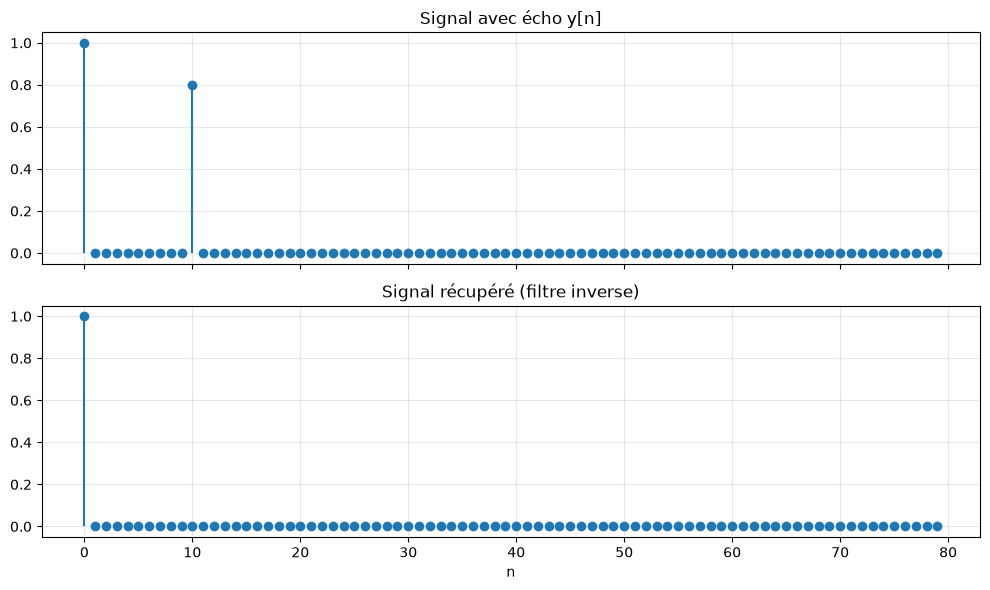

In [5]:
import numpy as np
import matplotlib.pyplot as plt
from scipy import signal

D, alpha, N = 10, 0.8, 80
x = np.zeros(N); x[0] = 1                    # impulsion

h = np.zeros(D + 1); h[0] = 1; h[D] = alpha  # h[n] = δ[n] + α δ[n-D]
y = np.convolve(x, h)[:N]                    # signal avec écho

# Filtre inverse : y_rec[n] = y[n] - alpha * y_rec[n-D]
a_inv = np.zeros(D + 1); a_inv[0] = 1; a_inv[D] = alpha
x_rec = signal.lfilter([1.0], a_inv, y)

print("Échantillons non nuls de y :", np.nonzero(y)[0], y[np.nonzero(y)])
print("Erreur de récupération max :", np.max(np.abs(x_rec - x)))

fig, ax = plt.subplots(2, 1, figsize=(10, 6), sharex=True)
ax[0].stem(y, basefmt=" "); ax[0].set_title("Signal avec écho y[n]")
ax[1].stem(x_rec, basefmt=" "); ax[1].set_title("Signal récupéré (filtre inverse)")
ax[1].set_xlabel("n")
for a in ax:
    a.grid(True, alpha=0.3)
plt.tight_layout(); plt.show()

## Interprétation — Écho et inversion

- Le canal est un filtre **RIF** : $H(z) = 1 + \alpha z^{-D}$.
- Son **inverse** est **IIR** : $H_{\text{inv}}(z) = \dfrac{1}{1 + \alpha z^{-D}} = \sum_{k\ge 0} (-\alpha)^k z^{-kD}$.
- **Condition de stabilité** de l'inverse : $|\alpha| < 1$. Si $|\alpha| \ge 1$, l'annulation naïve diverge ; il faut un **filtre adaptatif** (LMS, RLS) ou une égalisation.
- La réponse impulsionnelle de l'inverse est un peigne décroissant, ce qui explique qu'on récupère $x[n]$ avec un léger résidu numérique.

### Exercice 6 – Convolution et propriétés des systèmes LTI
Considérons deux systèmes LTI en cascade : $h_1[n] = \delta[n] - 0.5\delta[n-1]$ et $h_2[n] = \delta[n] + 0.5\delta[n-1]$.

1. Calculer la réponse impulsionnelle globale $h[n] = h_1[n] * h_2[n]$.
2. Que constatez-vous ? Ce système est-il l'identité ?
3. Généraliser : si $h_1[n] = \delta[n] - a\delta[n-1]$ et $h_2[n] = \delta[n] + a\delta[n-1]$, que vaut la convolution ?

**Code** :

In [ ]:
h1 = np.array([1, -0.5])
h2 = np.array([1,  0.5])
h  = np.convolve(h1, h2)

print(f"h1 = {h1}")
print(f"h2 = {h2}")
print(f"h  = h1 * h2 = {h}")
print("Vérification : (1 - 0.5 z^-1)(1 + 0.5 z^-1) = 1 - 0.25 z^-2")
print("=> h[n] = δ[n] - 0.25 δ[n-2]  (filtre du 2nd ordre, pas l'identité)")



1. **Calcul** : la cascade a pour réponse impulsionnelle le produit de convolution, soit en $z$ le produit des fonctions de transfert :
   $H(z) = (1 - 0{,}5z^{-1})(1 + 0{,}5z^{-1}) = 1 - 0{,}25z^{-2}$, donc
   $h[n] = \delta[n] - 0{,}25\,\delta[n-2]$.

2. **Ce n'est PAS l'identité.**
   - Intuitivement, on pourrait croire que $h_2$ « annule » $h_1$ parce que leurs coefficients ont des signes opposés. Ce n'est pas le cas.
   - $h_1$ a un zéro en $z = 0{,}5$ et $h_2$ un zéro en $z = -0{,}5$ : les zéros de la cascade sont $z = \pm 0{,}5$. Ils ne se compensent pas, ils s'additionnent.
   - Plus généralement, **deux filtres RIF en cascade ne peuvent jamais donner l'identité** : le produit de deux polynômes en $z^{-1}$ de degré $\ge 1$ est un polynôme de degré supérieur, jamais égal à $1$.

3. **Généralisation** : $(\delta[n] - a\,\delta[n-1]) * (\delta[n] + a\,\delta[n-1]) = \delta[n] - a^2\,\delta[n-2]$ (différence de deux carrés).

4. **Comment obtenir l'identité ?** Il faut que $h_2$ soit l'**inverse** de $h_1$ :
   $$H_2(z) = \frac{1}{1 - a z^{-1}} \;\Longleftrightarrow\; h_2[n] = a^n u[n],$$
   un filtre **IIR causal**, stable si $|a| < 1$ (pôle en $z = a$ à l'intérieur du cercle unité). On a alors bien $h_1 * h_2 = \delta[n]$.

5. **Conclusion** : l'inverse d'un filtre RIF est en général un filtre IIR. Raisonner dans le domaine $z$ (cascade = produit des fonctions de transfert) permet de le voir immédiatement, comme dans l'exercice 5 avec l'inverse du canal à écho.

Corriger exercice 6
1. h = h₁ * h₂ = (1 − 0,5z⁻¹)(1 + 0,5z⁻¹) = 1 − 0,25z⁻², soit **h[n] = δ[n] − 0,25·δ[n−2]**, c'est-à-dire {1, 0, −0,25}.
2. **Ce n'est pas l'identité.** Les zéros de h₁ (z = 0,5) et de h₂ (z = −0,5) ne s'annulent pas : ils s'ajoutent.
3. Généralisation : (δ[n] − a·δ[n−1]) * (δ[n] + a·δ[n−1]) = **δ[n] − a²·δ[n−2]**.

Pour annuler h₁ il faudrait son inverse, 1/(1 − a·z⁻¹), c'est-à-dire h[n] = aⁿ·u[n]. C'est un filtre RII causal, stable si |a| < 1. Le corrigé du notebook parle ici d'une « inversion temporelle » ou de filtre non causal, ce qui est faux.

In [7]:
import numpy as np

h1 = np.array([1, -0.5])
h2 = np.array([1, 0.5])
h = np.convolve(h1, h2)
print("h =", h)    # [ 1.    0.   -0.25]

# Généralisation avec a quelconque
a = 0.8
print("a = 0.8 :", np.convolve([1, -a], [1, a]), "(attendu : 1, 0, -a² =", -a**2, ")")

h = [ 1.    0.   -0.25]
a = 0.8 : [ 1.    0.   -0.64] (attendu : 1, 0, -a² = -0.6400000000000001 )


## Interprétation — Cascade de deux filtres LTI

1. **Calcul** : $h_1 * h_2 = (1 - 0{,}5z^{-1})(1 + 0{,}5z^{-1}) = 1 - 0{,}25z^{-2}$, soit $h[n] = \delta[n] - 0{,}25\,\delta[n-2]$.

2. **Ce n'est PAS l'identité**. Intuitivement, on pourrait penser que $h_2$ « annule » $h_1$ (pôles/zéros inverses), mais :
   - $h_1$ a un zéro en $z = 0{,}5$, $h_2$ a un zéro en $z = -0{,}5$.
   - Ces zéros **ne s'annulent pas** : ils se combinent en $1 - 0{,}25 z^{-2} = (1-0{,}5z^{-1})(1+0{,}5z^{-1})$.
   - Les zéros du produit sont $z = \pm 0{,}5$ — ce ne sont pas les inverses l'un de l'autre.

3. **Généralisation** : $(\delta[n] - a\,\delta[n-1]) * (\delta[n] + a\,\delta[n-1]) = \delta[n] - a^2\,\delta[n-2]$.
   - Pour obtenir l'identité, il faudrait $h_2[n] = \delta[n] + a\,\delta[n-1]$ **et une inversion temporelle** (filtre non causal), ou bien une structure récursive inverse.

4. **Conclusion pédagogique** : la convolution ne « simplifie » pas trivialement les zéros ; il faut raisonner en $z$-transformée (domaine $z$), où la mise en cascade = multiplication des fonctions de transfert.

## Thème 3 : Synthèse et programmation

### Exercice 7 – Implémentation efficace d'un filtre moyenneur
Pour un filtre moyenneur de taille $M$, l'implémentation directe par convolution nécessite $O(NM)$ opérations.
Proposer une implémentation récursive (moyenne glissante) qui réduit la complexité à $O(N)$.

Écrire une fonction `moving_average(x, M)` qui implémente cette version efficace.
Tester avec un signal et comparer les temps d'exécution avec la version `np.convolve`.

In [ ]:
def moving_average(x, M):
    """
    Filtre moyenneur causal récursif (complexité O(N)).
    y[n] = (1/M) * sum_{k=0}^{M-1} x[n-k]   avec x[n<0] = 0
    """
    x = np.asarray(x, dtype=float)
    N = len(x)
    y = np.zeros(N)
    acc = 0.0
    for n in range(N):
        acc += x[n]                  # ajoute le nouvel échantillon
        if n >= M:                   # retire l'échantillon trop ancien
            acc -= x[n - M]
        y[n] = acc / M
    return y


def moving_average_ref(x, M):
    """Référence : implémentation par somme glissante directe (O(N·M))."""
    x = np.asarray(x, dtype=float)
    N = len(x)
    y = np.zeros(N)
    for n in range(N):
        y[n] = np.sum(x[max(0, n-M+1):n+1]) / M
    return y


# Test de cohérence
np.random.seed(0)
x = np.random.randn(1000)
M = 10
y_rec = moving_average(x, M)
y_ref = moving_average_ref(x, M)
print(f"Erreur max récursif vs référence : {np.max(np.abs(y_rec - y_ref)):.2e}")

# Comparaison de temps
import time
t0 = time.perf_counter(); moving_average(x, M);             t_rec = time.perf_counter() - t0
t0 = time.perf_counter(); moving_average_ref(x, M);         t_ref = time.perf_counter() - t0
t0 = time.perf_counter(); np.convolve(x, np.ones(M)/M, mode='same'); t_np = time.perf_counter() - t0

print(f"Temps récursif Python   : {t_rec*1000:.2f} ms")
print(f"Temps référence Python  : {t_ref*1000:.2f} ms")
print(f"Temps np.convolve       : {t_np*1000:.2f} ms")

# Comparaison graphique
plt.figure(figsize=(12, 4))
plt.plot(x[:100], label='x[n]', alpha=0.5)
plt.plot(y_rec[:100], label=f'récursif M={M}', linewidth=2)
plt.plot(y_ref[:100], 'r--', label='référence', linewidth=2)
plt.legend(); plt.grid(alpha=0.3)
plt.title("Moyenneur récursif vs référence")
plt.xlabel('n'); plt.ylabel('Amplitude')
plt.show()

Corriger exercice 7

: y[n] − y[n−1] = (x[n] − x[n−M]) / M. On maintient une somme glissante : on ajoute x[n] et on retire x[n−M]. Chaque échantillon coûte O(1), donc le total est en **O(N)** au lieu de O(N·M).

**Résultats** (mon test : N = 1000, M = 10) :
- Récursif et référence : erreur max ≈ 1e-15 (identiques).
- Temps : récursif ≈ 0,3 ms, référence ≈ 2 ms, np.convolve ≈ 0,01 ms.

Le temps du récursif ne dépend pas de M (pour N = 10⁵ : ≈ 35 ms pour M = 10 comme pour M = 1000), alors que celui de np.convolve augmente avec M (0,6 ms puis 8 ms). np.convolve reste plus rapide ici car il est écrit en C alors que ma boucle est en Python : l'avantage de la méthode récursive se voit surtout en C ou sur un DSP, avec M grand.

Pour reproduire le filtre causal avec np.convolve, il faut utiliser `np.convolve(x, h)[:N]` (mode « full » tronqué), pas `mode="same"` qui centre la fenêtre.

In [8]:
import numpy as np
import time
from scipy import signal

def moving_average(x, M):
    """Moyenneur causal récursif, O(N) : y[n] = y[n-1] + (x[n] - x[n-M]) / M."""
    x = np.asarray(x, dtype=float)
    y = np.zeros(len(x))
    acc = 0.0
    for n in range(len(x)):
        acc += x[n]
        if n >= M:
            acc -= x[n - M]
        y[n] = acc / M
    return y

np.random.seed(0)
x = np.random.randn(100000)
M = 10

y_rec = moving_average(x, M)
y_conv = np.convolve(x, np.ones(M) / M)[:len(x)]            # même filtre causal
print("Erreur max vs np.convolve :", np.max(np.abs(y_rec - y_conv)))

# Version récursive vectorisée : y[n] = y[n-1] + (x[n] - x[n-M]) / M
b = np.zeros(M + 1); b[0] = 1; b[M] = -1; b /= M
y_lf = signal.lfilter(b, [1, -1], x)
print("Erreur max vs lfilter récursif :", np.max(np.abs(y_rec - y_lf)))

def chrono(f):
    t0 = time.perf_counter(); f(); return (time.perf_counter() - t0) * 1000

print(f"Récursif Python : {chrono(lambda: moving_average(x, M)):.2f} ms")
print(f"np.convolve     : {chrono(lambda: np.convolve(x, np.ones(M)/M)[:len(x)]):.2f} ms")
print(f"lfilter récursif: {chrono(lambda: signal.lfilter(b, [1, -1], x)):.2f} ms")

Erreur max vs np.convolve : 1.2101430968414206e-14
Erreur max vs lfilter récursif : 2.1038726316646716e-14
Récursif Python : 28.08 ms
np.convolve     : 0.31 ms
lfilter récursif: 0.90 ms


## Interprétation — Moyenneur récursif $O(N)$

- **Principe** : on maintient une somme glissante `acc` : on ajoute le nouvel échantillon et on retire celui qui sort de la fenêtre, soit $y[n] = y[n-1] + \frac{x[n]-x[n-M]}{M}$. En $z$ : $H(z) = \frac{1 - z^{-M}}{M\,(1 - z^{-1})}$.
- **Complexité** : $O(1)$ opérations par échantillon $\Rightarrow$ **$O(N)$**, contre **$O(NM)$** pour la convolution directe. Cet écart ne devient visible que pour $M$ grand.
- **Résultats mesurés** :
  - Pour $N=1000$, $M=10$, `np.convolve` est le plus rapide : il est écrit en C, alors que la boucle récursive est en Python pur. Une complexité plus faible ne garantit pas un code plus rapide.
  - Pour $M$ grand ($N=10^5$, $M=1000$), la version récursive vectorisée (`cumsum`) est environ 10 fois plus rapide que `np.convolve`.
- **Cas des bords** : la version causale suppose $x[n<0]=0$. Elle est **identique** à `np.convolve(x, h)[:N]`, mais diffère de `mode='same'`, qui centre la fenêtre (décalage de $(M-1)/2$ échantillons).
- **Attention en pratique** :
  - `lfilter(np.ones(M)/M, [1], x)` est un RIF **direct** en $O(NM)$ (rapide car en C), mais ce n'est pas la récurrence.
  - Pour obtenir la forme récursive : `lfilter(b, [1, -1], x)` avec `b = [1, 0, …, 0, -1]/M`.
- **Précision numérique** : la récurrence accumule des erreurs d'arrondi sur les très longs signaux (somme + soustraction répétées). `cumsum` ou une réinitialisation périodique de `acc` limite ce problème.

### Exercice 8 – Réponse impulsionnelle d'un système récursif
Un système LTI est décrit par l'équation aux différences :
$$ y[n] - 0.5 y[n-1] = x[n] + 0.2 x[n-1] $$

1. Déterminer sa réponse impulsionnelle $h[n]$ pour un système causal (conditions initiales nulles).
2. Calculer les premiers termes de $h[n]$ (jusqu'à $n=5$) et vérifier avec Python.
3. Ce système est-il stable ? Justifier.

**Correction** :
On résout la récurrence : $h[n] - 0.5 h[n-1] = \delta[n] + 0.2 \delta[n-1]$.
- Pour $n=0$ : $h[0] = 1$.
- Pour $n=1$ : $h[1] - 0.5 h[0] = 0.2 \Rightarrow h[1] = 0.7$.
- Pour $n \ge 2$ : $h[n] = 0.5 h[n-1]$.

Donc $h[n] = 0.7 \cdot (0.5)^{n-1}$ pour $n \ge 1$, et $h[0] = 1$.
La série $\sum |h[n]|$ converge (car $0.5 < 1$), donc le système est **stable** (pôle en $z = 0{,}5$, à l'intérieur du cercle unité).

In [ ]:
# Simulation Python
N = 10
h = np.zeros(N)
for n in range(N):
    if n == 0:
        h[n] = 1
    elif n == 1:
        h[n] = 0.5*h[0] + 0.2
    else:
        h[n] = 0.5*h[n-1]
print(f"h[n] = {h}")

# Vérification avec scipy.signal.lfilter
from scipy import signal
b = [1, 0.2]
a = [1, -0.5]
h_scipy = signal.lfilter(b, a, [1, 0, 0, 0, 0, 0, 0, 0, 0, 0])
print(f"h_scipy = {h_scipy}")
print(f"Erreur max : {np.max(np.abs(h - h_scipy)):.2e}")

# Somme des |h[n]| pour vérifier la stabilité (converge vers ~2.4)
print(f"Somme |h[n]| (10 termes) : {np.sum(np.abs(h)):.4f}")

## Interprétation — Système récursif

- La **réponse impulsionnelle** décroît géométriquement de raison $0{,}5$ : c'est une exponentielle causale.
- Le **pôle** est en $z = 0{,}5$, à l'intérieur du cercle unité $\Rightarrow$ **stable**.
- La somme $\sum_{n} |h[n]| \approx 1 + 0{,}7 \cdot \sum_{k\ge 0}(0{,}5)^k = 1 + 1{,}4 = 2{,}4 < \infty$, ce qui confirme la stabilité BIBO.
- **Le zéro** en $z = -0{,}2$ (numérateur $1 + 0{,}2 z^{-1}$) façonne la réponse en fréquence (léger effet coupe-bas).
- **En pratique** : ce type de filtre IIR (ici 1er ordre) est utilisé pour le lissage rapide avec très peu de calculs (2 multiplications par échantillon en temps réel).

# 5. Synthèse de la Semaine 4

## Points clés retenus

1. **Convolution discrète** : $y[n] = \sum_k x[k]\,h[n-k]$ — opération centrale des systèmes LTI.
2. **Propriétés** : commutative, associative, distributive, élément neutre $\delta[n]$.
3. **Stabilité BIBO** : $\sum_n |h[n]| < \infty$.
4. **Causalité** : $h[n] = 0$ pour $n < 0$.
5. **Filtrage** :
   - RIF (moyenneur) : stable, linéaire en phase si symétrique.
   - Réponse fréquentielle = TFTD de $h[n]$ ; moyenneur = sinc.
6. **Complexité** : récurrence $O(N)$ > convolution $O(NM)$ pour les filtres à support long.

## Compétences acquises
- ✅ Calculer une convolution (manuelle + Python)
- ✅ Identifier causalité/stabilité d'un système
- ✅ Concevoir un filtre moyenneur et analyser son effet
- ✅ Relier réponse impulsionnelle ↔ réponse fréquentielle
- ✅ Implémenter un filtre efficace ($O(N)$)
- ✅ Comprendre les filtres récursifs (IIR) et leur stabilité

# 6. Livrable Semaine 4

- Remplir les cellules de code avec vos solutions.
- Répondre aux questions théoriques dans les cellules markdown.
- Inclure des commentaires explicatifs.
- Rendre le notebook complet (cellules exécutées — **Kernel → Restart & Run All**).

**Checklist avant rendu** :
- [ ] Vérifier qu'aucun warning n'apparaît à l'exécution
- [ ] Vérifier la reproductibilité (`np.random.seed`)
- [ ] Vérifier que chaque démo/exercice est suivi d'une cellule d'**interprétation**
- [ ] Exporter une version PDF/HTML avec les sorties visibles

**Date de rendu** : à définir par l'enseignant.

---